# <font color='yellow'>Operações Ponto-a-Ponto</font>

In [1]:
import cv2
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt


<font color='yellow'>Carregar as imagens (rose_grayscale.tif e bubbles_grayscale.jpg)</font>

<class 'numpy.ndarray'>
A imagem tem o formato (263, 264) e tem 263 linhas e 264 colunas.


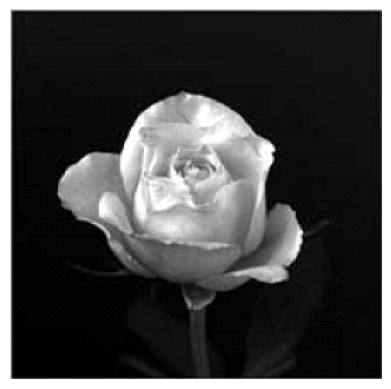

[[216 173 206 ... 206 200 195]
 [212 112  65 ...  59  71  97]
 [198  48  18 ...   5  11  62]
 ...
 [208  32   3 ...   0   2  46]
 [198  39   5 ...   0   0  48]
 [198 103  68 ...  65  68  97]]


In [2]:
# Carregar a imagem rose_grayscale.tif
img1 = plt.imread('rose_grayscale.tif')
print(type(img1))

M, N = img1.shape
print('A imagem tem o formato {} e tem {} linhas e {} colunas.'.format(img1.shape, M, N))

plt.imshow(img1, cmap='gray')
plt.axis('off')  # Desativar os eixos
plt.show()

print(img1)


<class 'numpy.ndarray'>
A imagem tem o formato (168, 174) e tem 168 linhas e 174 colunas.


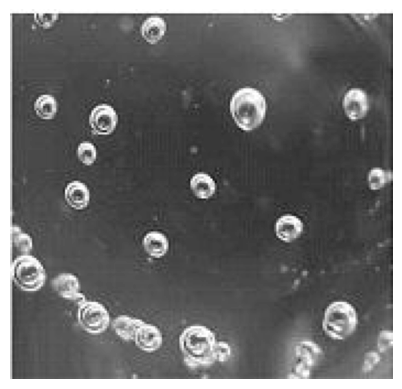

[[252 254 255 ... 255 255 252]
 [255 248 251 ... 255 252 245]
 [193 132 136 ... 142 136 126]
 ...
 [215 127 135 ... 176 170 162]
 [215 128 136 ... 173 170 164]
 [220 132 141 ... 179 177 171]]


In [3]:
# Carregar a imagem bubbles_grayscale.jpg
img2 = plt.imread('bubbles_grayscale.jpg')
print(type(img2))

M, N = img2.shape
print('A imagem tem o formato {} e tem {} linhas e {} colunas.'.format(img2.shape, M, N))

plt.imshow(img2, cmap='gray')
plt.axis('off') # Desativar os eixos
plt.show()

print(img2)


# <font color='yellow'>Visualização de histogramas</font>

Histograma é uma <font color='yellow'>representação gráfica da distribuição de intensidades de pixels em uma imagem</font>. Ele mostra a frequência com que diferentes níveis de intensidade ocorrem na imagem. Os eixos do histograma geralmente representam os valores de intensidade dos pixels (por exemplo, de 0 a 255 em uma imagem em escala de cinza) no eixo X e a contagem de pixels correspondente a cada intensidade, no eixo Y.

Dica: Utilize a função [plt.hist](https://matplotlib.org/3.3.1/api/_as_gen/matplotlib.pyplot.hist.html)

Ex: *plt.hist(myImg.flatten(), bins=XX, density=False, range=(0,255))*

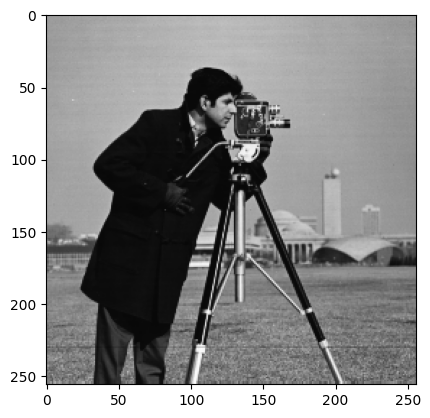

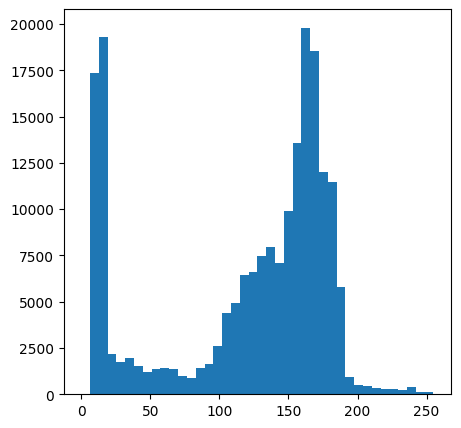

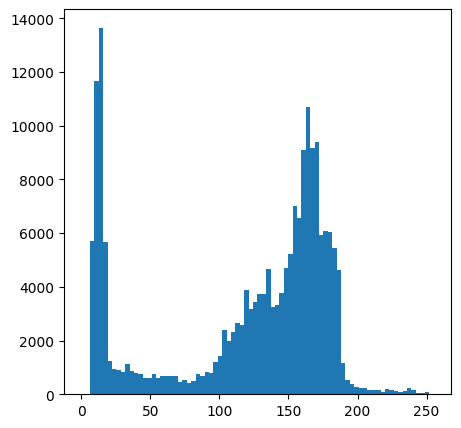

In [4]:
# Carregar a imagem "fotografo.png"
fotografo = cv2.imread('fotografo.png')

plt.imshow(fotografo)

# Plot do histograma com 40 divisões no eixo x
plt.figure(figsize=(5, 5))
histograma40 = plt.hist(fotografo.flatten(), bins=40, range=(0, 255))
# Plot do histograma com 80 divisões no eixo x
plt.figure(figsize=(5, 5))
histograma80 = plt.hist(fotografo.flatten(), bins=80, range=(0, 255))


# <font color='yellow'>Transformação linear de intensidades</font>

A transformação de intensidade em processamento de imagens refere-se a uma operação na qual os valores de intensidade dos pixels em uma imagem são modificados, geralmente de acordo com uma função específica. Essas transformações são aplicadas pixel a pixel e podem ser utilizadas para ajustar o contraste, brilho e outras características visuais da imagem.


**<font color='yellow'>1- Transformação Linear</font>**

\begin{align*}
g(x) &= c f(x) + b \\
\end{align*}

onde $c$ é uma constante que controla o contraste e $b$, o brilho.

Aplique uma transformação linear na imagem do "fotografo.png".

Antes:


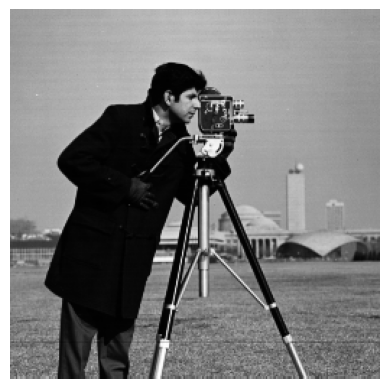

Depois:


/tmp/ipykernel_15317/2867502323.py:11: RuntimeWarning: overflow encountered in scalar add
  img[i, j] = c * img[i, j] + b


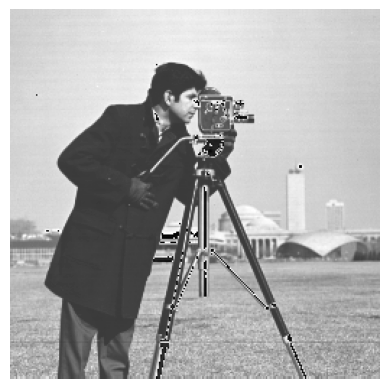

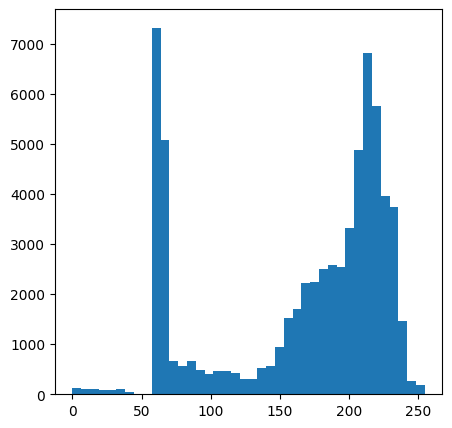

In [5]:
def transformacao_linear(img, c, b):
    img = cv2.imread('fotografo.png', cv2.IMREAD_GRAYSCALE)

    print('Antes:')
    plt.imshow(img, cmap='gray')
    plt.axis('off')
    plt.show()

    for i in range(img.shape[0]):
        for j in range(img.shape[1]):
            img[i, j] = c * img[i, j] + b
    return img


img_alterada = transformacao_linear('fotografo.png', 1, 50)

print('Depois:')
plt.imshow(img_alterada, cmap='gray')
plt.axis('off')
plt.show()

# Plot do histograma da imagem alterada
plt.figure(figsize=(5, 5))
histograma = plt.hist(img_alterada.flatten(), bins=40, range=(0, 255))


**<font color='yellow'>2- Transformação Linear Negativa</font>**

Uma transformação linear negativa pode ser usada para inverter as intensidades de uma imagem. Um exemplo de função de transformação linear negativa:

\begin{align*}
g(x) &= -1 f(x) + 255 \\
\end{align*}

Neste caso, o coeficiente de inclinação (a) é -1, o que indica a inversão, e o termo de deslocamento (b) é 255 para garantir que os valores resultantes estejam no intervalo válido de intensidades.

Aplique uma transformação linear negativa na imagem do "fotografo.png".

Antes:


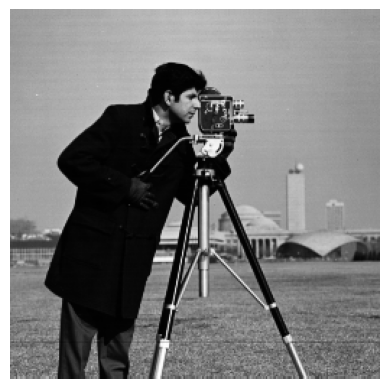

Depois:


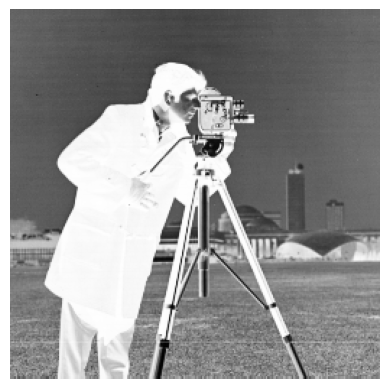

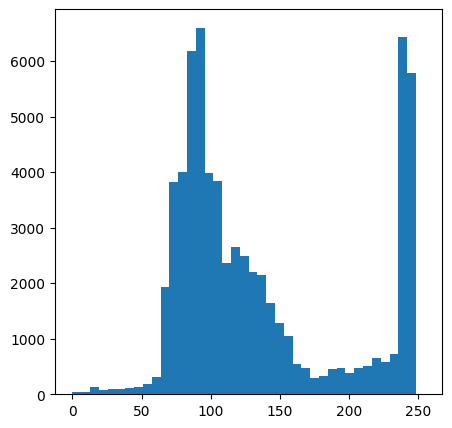

In [6]:
def transformacao_linear_negativa(img, c, b):
    img = cv2.imread('fotografo.png', cv2.IMREAD_GRAYSCALE)

    print('Antes:')
    plt.imshow(img, cmap='gray')
    plt.axis('off')
    plt.show()

    img = img.astype(np.int16)
    for i in range(img.shape[0]):
        for j in range(img.shape[1]):
            img[i, j] = c * img[i, j] + b
    return img


img_alterada = transformacao_linear_negativa('fotografo.png', -1, 255)

print('Depois:')
plt.imshow(img_alterada, cmap='gray')
plt.axis('off')
plt.show()

# Plot do histograma da imagem alterada
plt.figure(figsize=(5, 5))
histograma = plt.hist(img_alterada.flatten(), bins=40, range=(0, 255))


**<font color='yellow'>3- Transformação de contraste seletivo</font>**

Uma transformação de contraste seletivo pode ser aplicada para ajustar o contraste de diferentes faixas de intensidade na imagem.
Suponha que desejamos aumentar o contraste nos pixels de intensidade entre 100 e 200, mantendo as intensidades abaixo de 100 e acima de 200 praticamente inalteradas. Podemos usar a seguinte equação para uma transformação de contraste seletivo:

\begin{cases}
  a \cdot f(x, y) + b, & \text{se } c_1 \leq f(x, y) \leq c_2 \\
  f(x, y), & \text{caso contrário}
\end{cases}

Aplique uma transformação de constraste seletivo na imagem do "fotografo.png".



Antes:


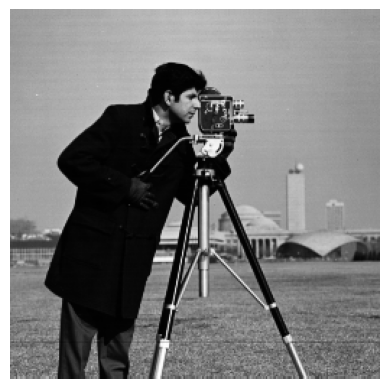

Depois:


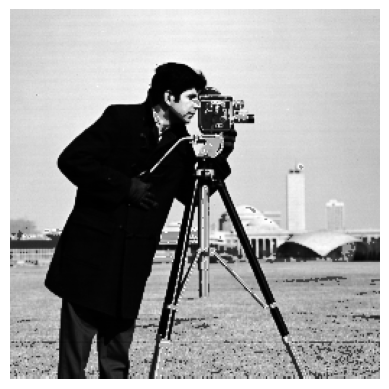

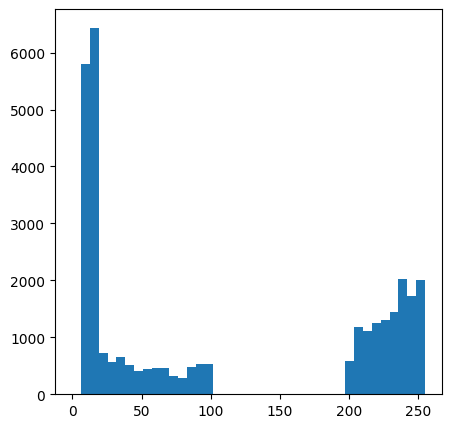

In [7]:
def transformacao_contraste_seletivo(img, c, b):
    img = cv2.imread('fotografo.png', cv2.IMREAD_GRAYSCALE)

    print('Antes:')
    plt.imshow(img, cmap='gray')
    plt.axis('off')
    plt.show()

    img = img.astype(np.int16)
    for i in range(img.shape[0]):
        for j in range(img.shape[1]):
            if 100 <= img[i, j] <= 200:
                img[i, j] = c * img[i, j] + b
    return img


img_alterada = transformacao_contraste_seletivo('fotografo.png', 1.5, 50)

print('Depois:')
plt.imshow(img_alterada, cmap='gray')
plt.axis('off')
plt.show()

# Plot do histograma da imagem alterada
plt.figure(figsize=(5, 5))
histograma = plt.hist(img_alterada.flatten(), bins=40, range=(0, 255))


**<font color='yellow'>4- Transformação linear de binarização</font>**

A transformação linear de binarização é frequentemente usada para converter uma imagem em tons de cinza em uma imagem binária, onde os pixels são transformados em valores 0 ou 255 com base em um limiar.

Aplique uma transformação linear de binarização na imagem do "fotografo.png".

Antes:


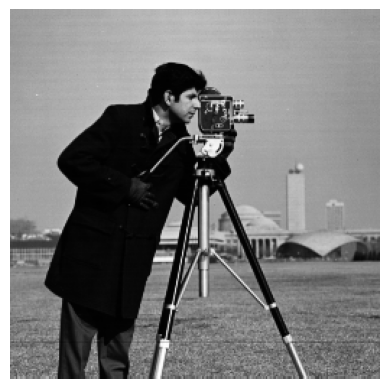

Depois:


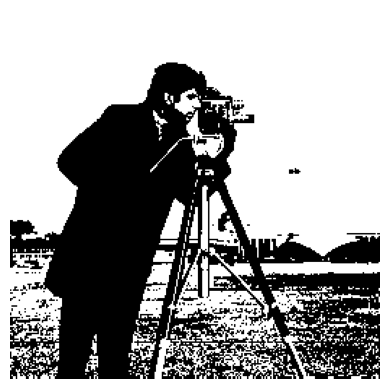

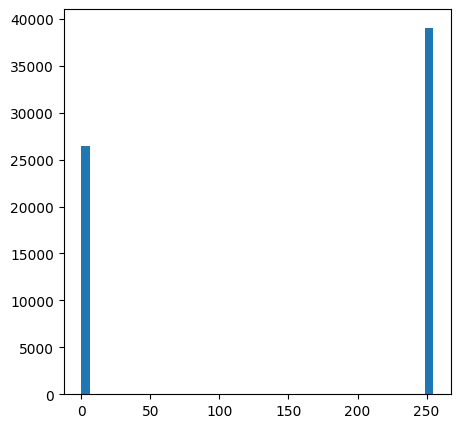

In [8]:
def transformacao_linear_binarizacao(img, threshold=128):
    img = cv2.imread('fotografo.png', cv2.IMREAD_GRAYSCALE)

    print('Antes:')
    plt.imshow(img, cmap='gray')
    plt.axis('off')
    plt.show()

    img = img.astype(np.int16)
    for i in range(img.shape[0]):
        for j in range(img.shape[1]):
            if img[i, j] >= threshold:
                img[i, j] = 255
            else:
                img[i, j] = 0
    return img


img_alterada = transformacao_linear_binarizacao('fotografo.png', 128)

print('Depois:')
plt.imshow(img_alterada, cmap='gray')
plt.axis('off')
plt.show()

# Plot do histograma da imagem alterada
plt.figure(figsize=(5, 5))
histograma = plt.hist(img_alterada.flatten(), bins=40, range=(0, 255))


## Transformação não-linear de intensidade

**<font color='yellow'>1- Transformação logarítmica</font>**

A transformação logarítmica é uma técnica frequentemente usada para expandir as intensidades dos pixels em imagens com ampla variação de intensidade. Isso é útil, por exemplo, quando há detalhes importantes em áreas mais escuras da imagem.

\begin{align*}
g(x) &= c . ln[f(x, y) + 1] \\
\end{align*}

Aplique uma transformação logarítmica na imagem do "fotografo.png".

Antes:


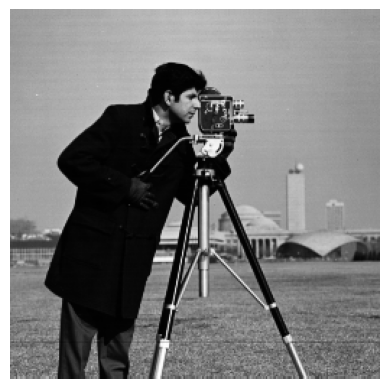

Depois:


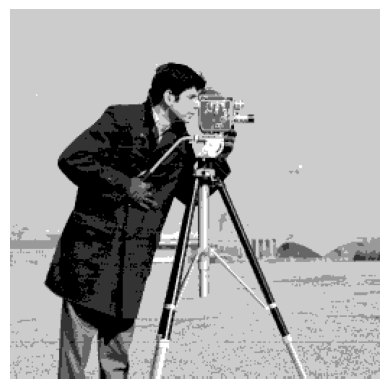

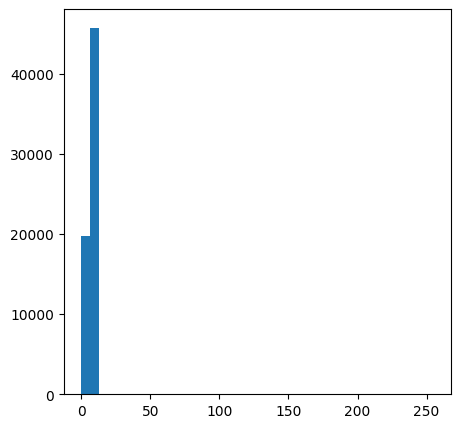

In [9]:
def transformacao_logaritmica(img, c):
    img = cv2.imread('fotografo.png', cv2.IMREAD_GRAYSCALE)

    print('Antes:')
    plt.imshow(img, cmap='gray')
    plt.axis('off')
    plt.show()

    for i in range(img.shape[0]):
        for j in range(img.shape[1]):
            img[i, j] = c * np.log(1 + img[i, j])
    return img


img_alterada = transformacao_logaritmica('fotografo.png', 1.5)

print('Depois:')
plt.imshow(img_alterada, cmap='gray')
plt.axis('off')
plt.show()

# Plot do histograma da imagem alterada
plt.figure(figsize=(5, 5))
histograma = plt.hist(img_alterada.flatten(), bins=40, range=(0, 255))


**<font color='yellow'>2- Transformação de potência</font>**

A transformação de potência é uma técnica frequentemente usada para ajustar o contraste em imagens, especialmente quando há uma predominância de intensidades em uma determinada faixa.

\begin{align*}
g(x) &= c f(x, y)^Γ \\
\end{align*}

Aplique uma transformação de potência na imagem do "fotografo.png".

Antes:


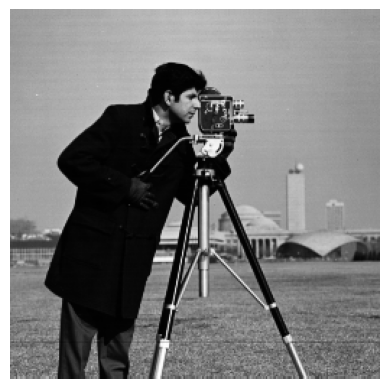

Depois:


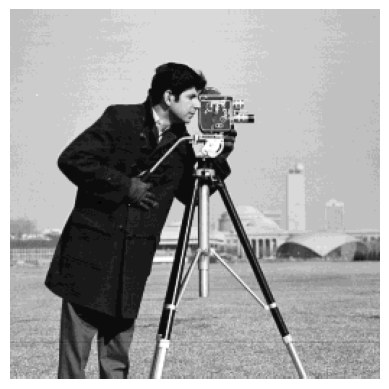

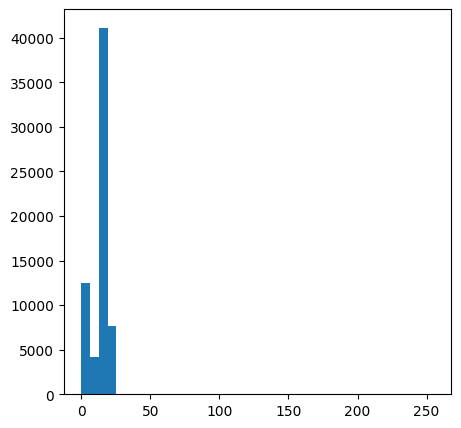

In [12]:
def transformacao_potencia(img, c, p):
    img = cv2.imread('fotografo.png', cv2.IMREAD_GRAYSCALE)

    print('Antes:')
    plt.imshow(img, cmap='gray')
    plt.axis('off')
    plt.show()

    for i in range(img.shape[0]):
        for j in range(img.shape[1]):
            img[i, j] = c * np.power(img[i, j], p)
    return img

img_alterada = transformacao_potencia('fotografo.png', 1.5, 0.5)

print('Depois:')
plt.imshow(img_alterada, cmap='gray')
plt.axis('off')
plt.show()

# Plot do histograma da imagem alterada
plt.figure(figsize=(5, 5))
histograma = plt.hist(img_alterada.flatten(), bins=40, range=(0, 255))


# <font color='yellow'>Equalização de Histograma</font>

Utilize a função [equalizeHist](https://docs.opencv.org/4.x/d5/daf/tutorial_py_histogram_equalization.html) da Open Computer Vision Library.

Aplique equalização de histograma na imagem do "fotografo.png".

Antes:


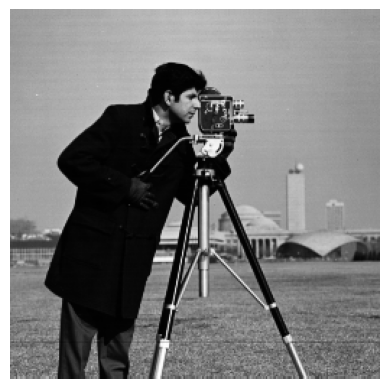

Depois:


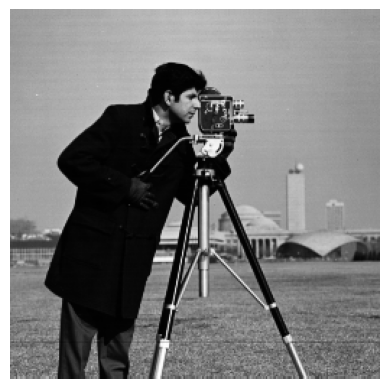

In [11]:
img = cv2.imread('fotografo.png', cv2.IMREAD_GRAYSCALE)

print('Antes:')
plt.imshow(img, cmap='gray')
plt.axis('off')
plt.show()

img_equalizada = cv2.equalizeHist(img)

print('Depois:')
plt.imshow(img, cmap='gray')
plt.axis('off')
plt.show()
